# Circular waveguide attenuation
The aim of this example is to reproduce the attenuation coefficients as presented in Balanis' Advanced Engineering Electromagnetics -- Third edition, Constantine A. Balanis, Wiley, 2024.

The 2 figures are shown on page 495.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

import skrf as rf
from skrf.frequency import Frequency
from skrf.media import CircularWaveguide

rf.stylely()
# plot formatting
plt.rcParams['lines.linewidth'] = 1

In [2]:
sigma = 5.7e7
radius_list = [1.5e-2, 3e-2]
mode_list = [
    ['TE', 1, 1],
    ['TE', 0, 2],
    ['TE', 1, 1],
    ['TE', 2, 1],
    ['TM', 0, 1],
    ['TM', 1, 1]
]

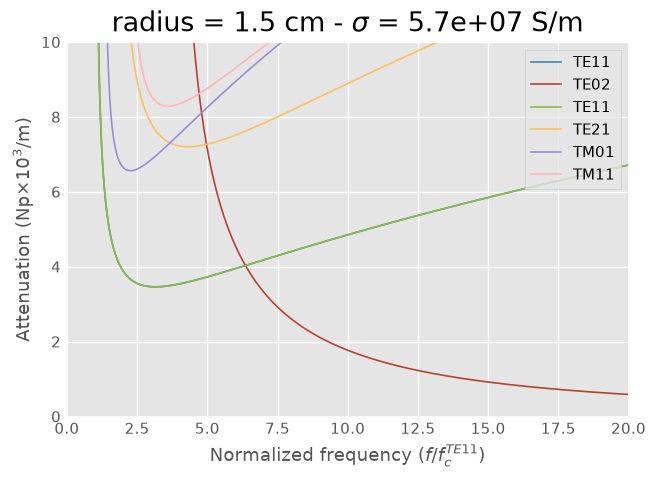

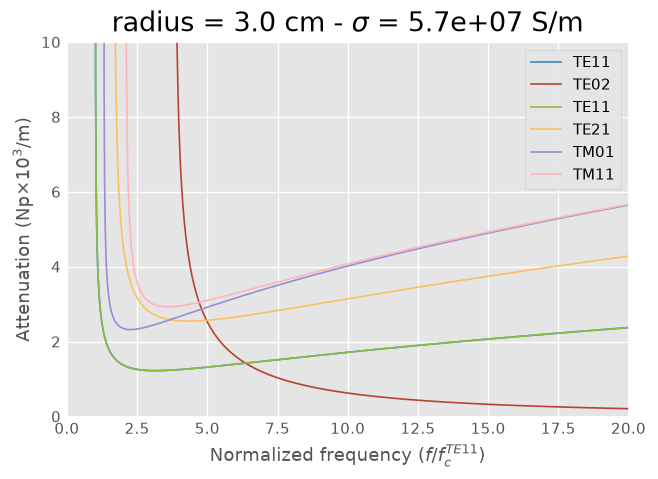

In [3]:
for radius in radius_list:
    fig, ax = plt.subplots()
    wg = CircularWaveguide(r=radius, m=1, n=1)
    fcTE11 = wg.f_cutoff
    fmax = fcTE11 * 20
    for mode_type, m, n in mode_list:
        wg_plot = CircularWaveguide(r=radius, m=m, n=n, mode_type=mode_type, rho=1/sigma)
        wg_plot.frequency = Frequency(wg_plot.f_cutoff+1, fmax, 1001, 'Hz')
        label = "%s%d%d" % (mode_type, m, n)
        plt.plot(wg_plot.frequency.f/fcTE11, (wg_plot.alpha)*1e3, label=label)

    ax.set_ylim(0, 10)
    ax.set_xlim(0, 20)
    ax.legend(loc='upper right')
    ax.set_xlabel('Normalized frequency ($f/f_c^{TE11}$)')
    ax.set_ylabel('Attenuation (Np×$10^3$/m)')
    ax.set_title(r'radius = %.1f cm - $\sigma$ = %g S/m' % (radius*1e2, sigma))